In [77]:
import matplotlib.pyplot as plt
import numpy as np
import csv
import pandas as pd
from scipy.stats import linregress

In [ ]:
pokedex = pd.read_csv("pokemon.csv")

In [ ]:
x_values = []
y_values = []
labels = []

for _, pokemon in pokedex.iterrows():

    previous_id = pokemon["evolves_from_id"]

    if pd.isna(previous_id):
        continue

    previous = pokedex[pokedex["id"] == previous_id]

    if previous.empty:
        continue

    previous = previous.iloc[0]

    h1 = previous["height_m"]
    h2 = pokemon["height_m"]
    w1 = previous["weight_kg"]
    w2 = pokemon["weight_kg"]

    height_ratio = h2 / h1
    weight_ratio = w2 / w1

    x_values.append(np.log(height_ratio))
    y_values.append(np.log(weight_ratio))

    labels.append(previous["name"] + " -> " + pokemon["name"])

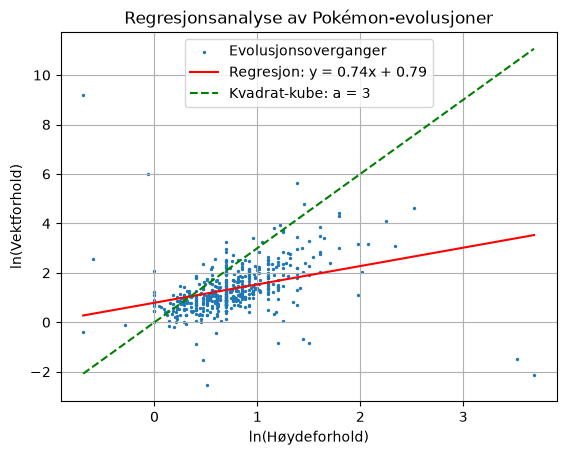

In [ ]:
result = linregress(x_values, y_values)

a = result.slope
b = result.intercept

plt.scatter(x_values, y_values, s = 2, label="Evolusjonsoverganger",)

x_line = np.linspace(min(x_values), max(x_values), 100)
y_line = a * x_line + b

plt.plot(x_line, y_line, color = "red", label = f"Regresjon: y = {a:.2f}x + {b:.2f}")

plt.plot(x_line, 3 * x_line, color = "green", linestyle = "--", label = "Kvadrat-kube-loven: a = 3")

plt.xlabel("ln(Høydeforhold)")
plt.ylabel("ln(Vektforhold)")
plt.title("Regresjonsanalyse av Pokémon-evolusjoner")
plt.legend()
plt.grid()
plt.show()


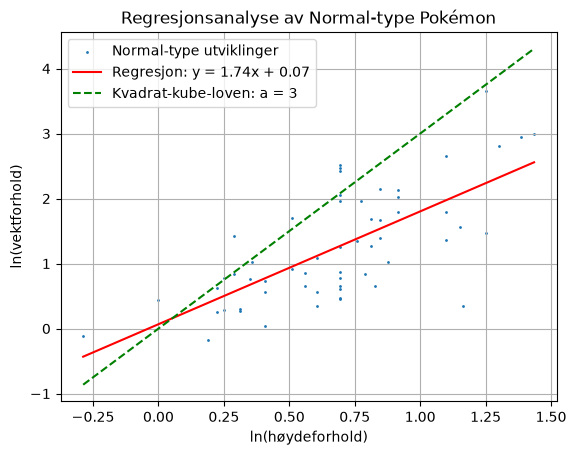

In [ ]:
x_values = []
y_values = []
labels = []

for _, pokemon in pokedex.iterrows():

    previous_id = pokemon["evolves_from_id"]

    if pd.isna(previous_id):
        continue

    previous = pokedex[pokedex["id"] == previous_id]

    if previous.empty:
        continue

    previous = previous.iloc[0]

    if not (pokemon["type1"] == "normal" or pokemon["type2"] == "normal"):
        continue

    if not (previous["type1"] == "normal" or previous["type2"] == "normal"):
        continue

    height1 = previous["height_m"]
    height2 = pokemon["height_m"]
    weight1 = previous["weight_kg"]
    weight2 = pokemon["weight_kg"]

    height_ratio = height2 / height1
    weight_ratio = weight2 / weight1

    x_values.append(np.log(height_ratio))
    y_values.append(np.log(weight_ratio))

    labels.append(previous["name"] + " -> " + pokemon["name"])

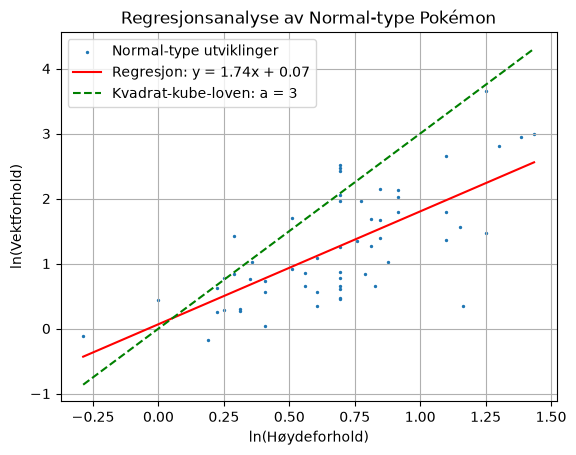

In [76]:
result = linregress(x_values, y_values)

a = result.slope
b = result.intercept

plt.scatter(x_values, y_values, s = 2, label = "Normal-type utviklinger")

x_line = np.linspace(min(x_values), max(x_values), 100)
y_line = a * x_line + b

plt.plot(x_line, y_line, color = "red", label = f"Regresjon: y = {a:.2f}x + {b:.2f}")

plt.plot(x_line, 3 * x_line, color = "green", linestyle = "--", label = "Kvadrat-kube-loven: a = 3")

plt.xlabel("ln(Høydeforhold)")
plt.ylabel("ln(Vektforhold)")
plt.title("Regresjonsanalyse av Normal-type Pokémon")
plt.legend()
plt.grid()
plt.show()
